# درس ۳ — مهندسی ویژگی‌ها (Feature Engineering)
## پروژه تخمین هزینه حمل Atramart

در درس قبل `X` و `y` را جدا کردیم و داده را به آموزش و آزمون تقسیم کردیم. حالا باید داده‌ها را به شکلی تبدیل کنیم که الگوریتم‌های یادگیری ماشین بتوانند با آن‌ها محاسبه انجام دهند.

**مهندسی ویژگی** یعنی آماده‌سازی یا ساختن اطلاعات ورودی مفید برای مدل. در این درس سه کار انجام می‌دهیم:
1. از تاریخ، ویژگی‌های عددی استخراج می‌کنیم.
2. مقدار خالی یک ستون دسته‌ای را مدیریت می‌کنیم.
3. متن‌های دسته‌ای را به ستون‌های عددی تبدیل می‌کنیم.

> دیتاست فعلی مصنوعی و آموزشی است؛ فعلاً روش را تمرین می‌کنیم.

## ۱. کتابخانه‌ها و آماده‌کردن X و y

این نوت‌بوک مستقل است؛ بنابراین فایل را دوباره می‌خوانیم و تقسیم آموزش/آزمون را با همان تنظیمات درس قبل می‌سازیم. `random_state=42` کمک می‌کند همان تقسیم تکرار شود.

In [3]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_PATH = Path("../data/raw/atramart_random_shipping_dataset.csv")
df = pd.read_csv(DATA_PATH, parse_dates=["shipping_date"])

TARGET = "real_cost"
FEATURES = [
    "weight", "items_count", "base_city", "destination_city",
    "destination_region", "product_category", "shipping_date",
    "package_count", "carrier_name", "service_type"
]

X = df[FEATURES].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (2400, 10)
X_test : (600, 10)


## ۲. استخراج ویژگی از تاریخ

ستون `shipping_date` از نوع تاریخ است. بسیاری از مدل‌ها مستقیماً با تاریخ خام کار نمی‌کنند؛ بنابراین از آن اطلاعات ساده‌تری استخراج می‌کنیم:

- `shipping_month`: ماه ارسال (۱ تا ۱۲)
- `shipping_dayofweek`: روز هفته (دوشنبه=۰ تا یکشنبه=۶ در pandas)
- `shipping_is_weekend`: آیا روز ارسال جمعه/شنبه است؟ (در داده‌های میلادی، جمعه=۴ و شنبه=۵)

**نکته:** در این تمرین آخرهفته ایران را جمعه و شنبه در نظر می‌گیریم. pandas روز هفته را با تقویم میلادی شماره‌گذاری می‌کند؛ برای تاریخ‌های شمسی/تعطیلات رسمی باید بعداً تقویم دقیق ایران را اضافه کنیم.

In [4]:
for data in (X_train, X_test):
    data["shipping_month"] = data["shipping_date"].dt.month
    data["shipping_dayofweek"] = data["shipping_date"].dt.dayofweek
    data["shipping_is_weekend"] = data["shipping_dayofweek"].isin([4, 5]).astype(int)

# تاریخ خام را بعد از استخراج ویژگی‌ها حذف می‌کنیم
X_train = X_train.drop(columns=["shipping_date"])
X_test = X_test.drop(columns=["shipping_date"])

X_train[["shipping_month", "shipping_dayofweek", "shipping_is_weekend"]].head()

C:\Users\Atramart\AppData\Local\Temp\ipykernel_8980\2523914563.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["shipping_dayofweek"] = data["shipping_date"].dt.dayofweek
C:\Users\Atramart\AppData\Local\Temp\ipykernel_8980\2523914563.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["shipping_dayofweek"] = data["shipping_date"].dt.dayofweek


,shipping_month,shipping_dayofweek,shipping_is_weekend
642,9,6,0
700,7,6,0
226,11,4,1
1697,11,4,1
1010,5,1,0


## ۳. مدیریت مقدارهای خالی در destination_region

برای سفارش‌های خارج از تهران، ممکن است `destination_region` خالی باشد؛ چون منطقه/محله فقط برای تحویل‌های داخل تهران معنا دارد.

در این تمرین، مقدار خالی را با متن `ثبت نشده` جایگزین می‌کنیم. این به معنی حدس زدن منطقه نیست؛ فقط یک برچسب مشخص برای «اطلاعات موجود نیست» می‌سازیم.

In [5]:
X_train["destination_region"] = X_train["destination_region"].fillna("ثبت نشده")
X_test["destination_region"] = X_test["destination_region"].fillna("ثبت نشده")

print("مقادیر خالی train:", X_train.isna().sum().sum())
print("مقادیر خالی test :", X_test.isna().sum().sum())

مقادیر خالی train: 0
مقادیر خالی test : 0


## ۴. تبدیل متن دسته‌ای به عدد: One-Hot Encoding

ستون‌هایی مثل `carrier_name` متن هستند: Post، Tipax، Cargo و Courier. مدل‌های معمولی نمی‌توانند این متن‌ها را مستقیماً در محاسبات عددی استفاده کنند.

یک روش ساده **One-Hot Encoding** است: برای هر دسته یک ستون صفر/یک می‌سازیم. مثلاً ستون `carrier_name_Post` اگر شرکت پست باشد ۱ و در غیر این صورت ۰ می‌شود.

از `get_dummies` استفاده می‌کنیم. آن را فقط روی داده آموزش اجرا می‌کنیم، سپس ستون‌های آزمون را با ستون‌های آموزش هماهنگ می‌کنیم. این کار باعث می‌شود ساختار ورودی آزمون دقیقاً با آموزش یکی باشد.

In [6]:
categorical_columns = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
print("ستون‌های دسته‌ای:", categorical_columns)

X_train_encoded = pd.get_dummies(
    X_train, columns=categorical_columns, dtype=int
)
X_test_encoded = pd.get_dummies(
    X_test, columns=categorical_columns, dtype=int
)

# ستون‌های test را با ستون‌های train یکسان می‌کنیم
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns, fill_value=0
)

print("شکل X_train_encoded:", X_train_encoded.shape)
print("شکل X_test_encoded :", X_test_encoded.shape)

ستون‌های دسته‌ای: ['base_city', 'destination_city', 'destination_region', 'product_category', 'carrier_name', 'service_type']
شکل X_train_encoded: (2400, 35)
شکل X_test_encoded : (600, 35)


C:\Users\Atramart\AppData\Local\Temp\ipykernel_8980\2146188444.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(include=["object", "category"]).columns.tolist()


## ۵. بررسی نتیجه

حالا ورودی‌های آماده‌شده باید عددی باشند و تعداد ستون‌های train و test برابر باشد. `select_dtypes` کمک می‌کند ستون‌هایی را پیدا کنیم که هنوز نوع متنی دارند.

In [7]:
print("ستون‌های غیرعددی در train:")
print(X_train_encoded.select_dtypes(exclude="number").columns.tolist())

print("آیا ستون‌های train و test کاملاً یکسان‌اند؟")
print(X_train_encoded.columns.equals(X_test_encoded.columns))

X_train_encoded.head()

ستون‌های غیرعددی در train:
[]
آیا ستون‌های train و test کاملاً یکسان‌اند؟
True


,weight,items_count,package_count,shipping_month,shipping_dayofweek,shipping_is_weekend,base_city_Tehran,destination_city_Ahvaz,destination_city_Isfahan,destination_city_Mashhad,...,product_category_Networking,product_category_Peripheral,product_category_Printer,carrier_name_Cargo,carrier_name_Courier,carrier_name_Post,carrier_name_Tipax,service_type_Express,service_type_Normal,service_type_Special
642,278,3,1,9,6,0,1,0,1,0,...,0,1,0,0,1,0,0,0,1,0
700,265,2,1,7,6,0,1,0,0,0,...,0,1,0,0,0,0,1,0,1,0
226,2290,1,2,11,4,1,1,0,0,0,...,0,1,0,0,1,0,0,1,0,0
1697,1404,1,1,11,4,1,1,0,0,1,...,0,0,0,0,0,1,0,0,1,0
1010,1793,2,1,5,1,0,1,0,0,0,...,0,1,0,0,0,1,0,0,1,0


## ۶. تمرین پایان درس

۱. چرا `shipping_date` خام را حذف کردیم و به‌جایش ماه و روز هفته ساختیم؟
۲. One-Hot Encoding چه مشکلی را حل می‌کند؟
۳. چرا ستون‌های `X_test_encoded` را با ستون‌های `X_train_encoded` هماهنگ کردیم؟
۴. خروجی دو بررسی آخر چه چیزی را درباره آماده بودن داده‌ها نشان می‌دهد؟

**توقف اینجا:** هنوز مدل را آموزش نمی‌دهیم. ابتدا این درس را اجرا کن و تمرین‌ها را پاسخ بده؛ سپس به سراغ ساخت اولین مدل می‌رویم.

In [8]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_encoded, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [22]:
y_pred = model.predict(X_test_encoded)

y_pred[:10]

array([191299.89, 219224.84, 143092.12, 139556.59, 275031.33, 166417.54,
       185748.49, 213981.98, 208693.95, 183073.8 ])

In [10]:
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 17664.228066666667
RMSE: 22669.253766377562
R2: 0.8687452740975261


In [ ]:
from sklearn.metrics import mean_absolute_error

train_pred = model.predict(X_train_encoded)
test_pred = model.predict(X_test_encoded)

train_mae = mean_absolute_error(y_train, train_pred)
test_mae = mean_absolute_error(y_test, test_pred)

# if Test MAE >>> Train MAE ----> model has overfitting probably
print("Train MAE:", train_mae)
print("Test MAE:", test_mae) 

Train MAE: 6654.537466666668
Test MAE: 17664.228066666667


In [12]:
baseline_pred = [y_train.mean()] * len(y_test)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

print("Baseline MAE:", baseline_mae)
print("Model MAE:", test_mae)

Baseline MAE: 48189.062661111115
Model MAE: 17664.228066666667


In [14]:
import pandas as pd

results = pd.DataFrame({
    "actual": y_test,
    "predicted": test_pred
})

results["error"] = (
    results["actual"] - results["predicted"]
)

results["absolute_error"] = (
    results["error"].abs()
)

results.head(10)

,actual,predicted,error,absolute_error
1801,233567,191299.89,42267.11,42267.11
1190,236803,219224.84,17578.16,17578.16
1817,136726,143092.12,-6366.12,6366.12
251,160074,139556.59,20517.41,20517.41
2505,311449,275031.33,36417.67,36417.67
1117,168681,166417.54,2263.46,2263.46
1411,158159,185748.49,-27589.49,27589.49
2113,252681,213981.98,38699.02,38699.02
408,178166,208693.95,-30527.95,30527.95
2579,170324,183073.80,-12749.80,12749.80


In [15]:
worst_predictions = results.sort_values(
    by="absolute_error",
    ascending=False
)

worst_predictions.head(10)

,actual,predicted,error,absolute_error
2663,372846,246892.10,125953.90,125953.90
881,497392,406497.29,90894.71,90894.71
2370,471633,386790.19,84842.81,84842.81
436,386582,319387.03,67194.97,67194.97
2012,256941,195306.12,61634.88,61634.88
2957,210133,149966.64,60166.36,60166.36
2851,324639,266596.41,58042.59,58042.59
1725,197435,255185.99,-57750.99,57750.99
1399,105158,159773.11,-54615.11,54615.11
2700,52978,107503.53,-54525.53,54525.53


In [20]:
import pandas as pd

feature_importance = pd.DataFrame({
    "feature": X_train_encoded.columns,
    "importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

feature_importance = feature_importance.reset_index(drop=True)
feature_importance.head(15)

,feature,importance
0,destination_city_Tehran,0.182424
1,service_type_Normal,0.180412
2,weight,0.151796
3,destination_region_ثبت نشده,0.142397
4,package_count,0.132742
5,carrier_name_Post,0.051228
6,carrier_name_Cargo,0.044705
7,items_count,0.017857
8,shipping_month,0.014454
9,service_type_Special,0.012222


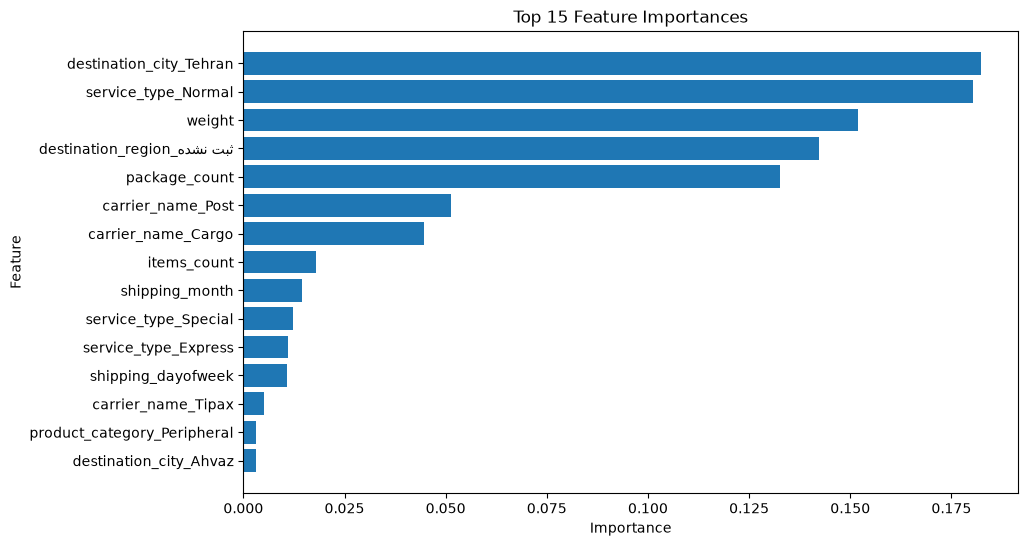

In [21]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by="importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances")

plt.show()

In [23]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

model_limited = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

model_limited.fit(X_train_encoded, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [24]:
train_pred_limited = model_limited.predict(X_train_encoded)
test_pred_limited = model_limited.predict(X_test_encoded)

train_mae_limited = mean_absolute_error(
    y_train,
    train_pred_limited
)

test_mae_limited = mean_absolute_error(
    y_test,
    test_pred_limited
)

print("Limited Train MAE:", train_mae_limited)
print("Limited Test MAE:", test_mae_limited)

Limited Train MAE: 8251.26529154503
Limited Test MAE: 17650.504166470928


In [25]:
depths = [5, 8, 12, 16, 20, None]

comparison = []

for depth in depths:
    temp_model = RandomForestRegressor(
        n_estimators=100,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )

    temp_model.fit(X_train_encoded, y_train)

    train_prediction = temp_model.predict(X_train_encoded)
    test_prediction = temp_model.predict(X_test_encoded)

    train_mae = mean_absolute_error(
        y_train,
        train_prediction
    )

    test_mae = mean_absolute_error(
        y_test,
        test_prediction
    )

    comparison.append({
        "max_depth": depth,
        "train_mae": train_mae,
        "test_mae": test_mae
    })

comparison_df = pd.DataFrame(comparison)

comparison_df

,max_depth,train_mae,test_mae
0,5.0,19834.481432,20906.713137
1,8.0,13361.806924,17790.934225
2,12.0,8251.265292,17650.504166
3,16.0,6818.973107,17799.238703
4,20.0,6663.057163,17686.115902
5,NaN,6654.537467,17664.228067


In [26]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
import numpy as np

cv_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

scores = cross_val_score(
    cv_model,
    X_train_encoded,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

mae_scores = -scores

print("MAE for each fold:", mae_scores)
print("Mean CV MAE:", mae_scores.mean())
print("Standard Deviation:", mae_scores.std())

MAE for each fold: [18053.37502624 17854.53585571 17300.30081907 18525.38140791
 18931.33579824]
Mean CV MAE: 18132.98578143395
Standard Deviation: 560.1024115352409


In [27]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

param_grid = {
    "max_depth": [8, 12, 16],
    "min_samples_leaf": [1, 2, 4]
}

base_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=1
)

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_encoded, y_train)

Fitting 5 folds for each of 9 candidates, totalling 45 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [8, 12, ...], 'min_samples_leaf': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits

In [28]:
print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV MAE:")
print(-grid_search.best_score_)

Best Parameters:
{'max_depth': 16, 'min_samples_leaf': 1}
Best CV MAE:
18123.65314792971


In [29]:
grid_results = pd.DataFrame(grid_search.cv_results_)

grid_results[
    [
        "param_max_depth",
        "param_min_samples_leaf",
        "mean_test_score",
        "std_test_score"
    ]
].sort_values(
    by="mean_test_score",
    ascending=False
)

,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score
6,16,1,-18123.653148,571.257065
4,12,2,-18127.665393,475.885388
3,12,1,-18132.985781,560.102412
0,8,1,-18153.031061,464.921875
1,8,2,-18174.967752,435.592322
7,16,2,-18188.568141,468.400413
5,12,4,-18290.050245,437.777631
8,16,4,-18293.163600,440.706446
2,8,4,-18325.971510,395.193112


In [30]:
grid_results["mean_mae"] = -grid_results["mean_test_score"]

grid_results[
    [
        "param_max_depth",
        "param_min_samples_leaf",
        "mean_mae",
        "std_test_score"
    ]
].sort_values(by="mean_mae")

,param_max_depth,param_min_samples_leaf,mean_mae,std_test_score
6,16,1,18123.653148,571.257065
4,12,2,18127.665393,475.885388
3,12,1,18132.985781,560.102412
0,8,1,18153.031061,464.921875
1,8,2,18174.967752,435.592322
7,16,2,18188.568141,468.400413
5,12,4,18290.050245,437.777631
8,16,4,18293.163600,440.706446
2,8,4,18325.971510,395.193112


In [31]:
best_model = grid_search.best_estimator_

best_test_pred = best_model.predict(X_test_encoded)

best_test_mae = mean_absolute_error(
    y_test,
    best_test_pred
)

print("Best Model Test MAE:", best_test_mae)

Best Model Test MAE: 17799.238702950082


In [33]:
best_test_pred = best_model.predict(X_test_encoded)

results = pd.DataFrame({
    "actual": y_test,
    "predicted": best_test_pred
})

results["error"] = results["actual"] - results["predicted"]
results["underprediction"] = results["error"].clip(lower=0)

under_count = (results["error"] > 0).sum()
under_rate = (results["error"] > 0).mean()

mean_underprediction = results["underprediction"].mean()
max_underprediction = results["underprediction"].max()

print("Underpredicted orders:", under_count)
print("Underprediction rate:", under_rate)
print("Mean underprediction across all orders:", mean_underprediction)
print("Maximum underprediction:", max_underprediction)

Underpredicted orders: 297
Underprediction rate: 0.495
Mean underprediction across all orders: 9094.09884712156
Maximum underprediction: 128184.54000000001


In [34]:
import numpy as np

margins = [0, 0.05, 0.10, 0.15, 0.20]

margin_results = []

for margin in margins:
    adjusted_pred = best_test_pred * (1 + margin)

    under_rate = (
        y_test > adjusted_pred
    ).mean()

    mae = mean_absolute_error(
        y_test,
        adjusted_pred
    )

    margin_results.append({
        "margin": margin,
        "underprediction_rate": under_rate,
        "mae": mae
    })

margin_df = pd.DataFrame(margin_results)

margin_df

,margin,underprediction_rate,mae
0,0.00,0.495000,17799.238703
1,0.05,0.338333,19771.262693
2,0.10,0.216667,24617.341818
3,0.15,0.106667,31685.153804
4,0.20,0.060000,40166.651086


In [35]:
import pandas as pd
import numpy as np

residuals = pd.DataFrame({
    "actual": y_test,
    "predicted": best_test_pred
})

residuals["error"] = (
    residuals["actual"] - residuals["predicted"]
)

residuals["underprediction"] = (
    residuals["error"].clip(lower=0)
)

residuals.head()

,actual,predicted,error,underprediction
1801,233567,190864.751848,42702.248152,42702.248152
1190,236803,218752.341824,18050.658176,18050.658176
1817,136726,143793.378180,-7067.378180,0.000000
251,160074,140046.189705,20027.810295,20027.810295
2505,311449,273513.666262,37935.333738,37935.333738


In [36]:
under_errors = residuals["underprediction"]

percentiles = [50, 75, 90, 95, 99]

percentile_values = np.percentile(
    under_errors,
    percentiles
)

percentile_df = pd.DataFrame({
    "percentile": percentiles,
    "error_amount": percentile_values
})

percentile_df

,percentile,error_amount
0,50,0.000000
1,75,15561.458569
2,90,26533.812531
3,95,36326.782250
4,99,60082.565783


In [37]:
margins = [0, 15561, 26534, 36327, 60083]

coverage_results = []

for margin in margins:
    adjusted_pred = best_test_pred + margin

    coverage = (y_test <= adjusted_pred).mean()

    average_extra = margin

    coverage_results.append({
        "margin_amount": margin,
        "coverage_rate": coverage,
        "average_extra_cost": average_extra
    })

coverage_df = pd.DataFrame(coverage_results)

coverage_df

,margin_amount,coverage_rate,average_extra_cost
0,0,0.505,0
1,15561,0.750,15561
2,26534,0.900,26534
3,36327,0.950,36327
4,60083,0.990,60083


In [38]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

models = {
    "Dummy": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        n_jobs=1
    )
}

model_results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train_encoded,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    mae_scores = -scores

    model_results.append({
        "model": name,
        "mean_cv_mae": mae_scores.mean(),
        "std_cv_mae": mae_scores.std()
    })

comparison_df = pd.DataFrame(model_results)

comparison_df.sort_values(
    by="mean_cv_mae"
)

,model,mean_cv_mae,std_cv_mae
1,Linear Regression,16970.357501,840.691821
3,Random Forest,18132.985781,560.102412
2,Decision Tree,24396.582917,792.620830
0,Dummy,50724.623787,1002.852246


In [39]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(
    X_train_encoded,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](35,)","[ 11.35, 2745.07, 35347.06,..., 1806.55,-41149.55, 39343. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](35,)","['weight','items_count','package_count',...,'service_type_Express', 'service_type_Normal','service_type_Special']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.246e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,35
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(28)


In [42]:
linear_pred = linear_model.predict(
    X_test_encoded
)

In [43]:
from sklearn.metrics import mean_absolute_error

linear_test_mae = mean_absolute_error(
    y_test,
    linear_pred
)

print("Linear Regression Test MAE:", linear_test_mae)

Linear Regression Test MAE: 16508.39869418962


In [44]:
linear_results = pd.DataFrame({
    "actual": y_test,
    "predicted": linear_pred
})

linear_results["error"] = (
    linear_results["actual"]
    - linear_results["predicted"]
)

linear_results["absolute_error"] = (
    linear_results["error"].abs()
)

linear_results.head(10)

,actual,predicted,error,absolute_error
1801,233567,194842.906960,38724.093040,38724.093040
1190,236803,222610.057923,14192.942077,14192.942077
1817,136726,151768.563929,-15042.563929,15042.563929
251,160074,144381.315725,15692.684275,15692.684275
2505,311449,288038.773049,23410.226951,23410.226951
1117,168681,163336.458640,5344.541360,5344.541360
1411,158159,171259.050015,-13100.050015,13100.050015
2113,252681,230292.307491,22388.692509,22388.692509
408,178166,209336.413744,-31170.413744,31170.413744
2579,170324,185004.983990,-14680.983990,14680.983990


In [46]:
print("Linear Regression Test MAE:", linear_test_mae)

print(
    "Underprediction rate:",
    (linear_results["error"] > 0).mean()
)

print(
    "Mean underprediction:",
    linear_results["error"].clip(lower=0).mean()
)

print(
    "Maximum underprediction:",
    linear_results["error"].clip(lower=0).max()
)

Linear Regression Test MAE: 16508.39869418962
Underprediction rate: 0.49833333333333335
Mean underprediction: 8451.044865374457
Maximum underprediction: 93243.5887962922
